## Task 2.1

In [1]:
import numpy as np

def data_points(n, m=1, mu=5, k=500):
    delta = mu / (2 * m)
    omega_0 = np.sqrt(k)
    omega = np.sqrt(omega_0**2 - delta**2)
    phi = np.arctan(- delta / omega)
    A = 1 / (2 * np.cos(phi))
    
    t = np.linspace(0, 0.5, n)
    x = np.exp(-delta * t) * (2 * A * np.cos(phi + omega * t))
    
    return t, x


for time, pos in zip(*data_points(10)):
    print(f"t = {time:.4f} -> x = {pos:.4f}")

t = 0.0000 -> x = 1.0000
t = 0.0556 -> x = 0.3797
t = 0.1111 -> x = -0.5394
t = 0.1667 -> x = -0.5974
t = 0.2222 -> x = 0.0654
t = 0.2778 -> x = 0.4901
t = 0.3333 -> x = 0.2320
t = 0.3889 -> x = -0.2379
t = 0.4444 -> x = -0.3124
t = 0.5000 -> x = 0.0008


## Task 2.2

In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


class Task22(nn.Module):
    def __init__(self, hidden_units=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden_units),
            nn.Tanh(),
            nn.Linear(hidden_units, 1),
            
        )

    def forward(self, x):
        y_pred = self.net(x)
        return y_pred

torch.set_default_dtype(torch.float64)
model = Task22(hidden_units=64)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
t_np, x_np = data_points(10)
t = torch.tensor(t_np, dtype=torch.float64).view(-1, 1)
x_data = torch.tensor(x_np, dtype=torch.float64).view(-1, 1)

# training
epochs = 2000
for epoch in range(epochs):
    optimizer.zero_grad()
    y_pred = model(t)
    loss = criterion(y_pred, x_data)
    loss.backward()
    optimizer.step()


t_infer = torch.linspace(0,1,100).view(-1,1) 
with torch.no_grad():
    y_infer = model(t_infer)

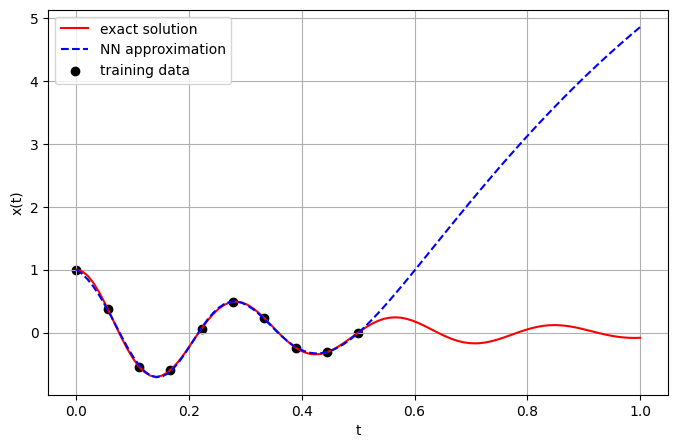

In [3]:
def exact_solution(t, m=1, mu=5, k=500):
    delta = mu / (2 * m)
    omega_0 = np.sqrt(k)
    omega = np.sqrt(omega_0**2 - delta**2)
    phi = np.arctan(-delta / omega)
    A = 1 / (2 * np.cos(phi))
    
    x = np.exp(-delta * t) * (2 * A * np.cos(phi + omega * t))
    
    return x

t_plot = t_infer.numpy().flatten()
y_plot = y_infer.numpy().flatten()
x_true = exact_solution(t_plot)

plt.figure(figsize=(8,5))
plt.plot(t_plot, x_true, label="exact solution", color="red")
plt.plot(t_plot, y_plot, "--", label="NN approximation", color="blue")
plt.scatter(t_np, x_np,color="black", label="training data")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.grid(True)
plt.show()

## Task 2.3

In [4]:
def network_output_and_derivatives(t, W1, b1, W2, b2):
    z = np.outer(t, W1) + b1
    
    sigma = np.tanh(z)
    sigma_1 = 1 - sigma**2
    sigma_2 = -2 * sigma * sigma_1
    
    y = np.sum(W2 * sigma, axis=1) + b2
    y_1 = np.sum(W2 * sigma_1 * W1, axis=1)
    y_2 = np.sum(W2 * sigma_2 * W1**2, axis=1)
    
    return y, y_1, y_2

def total_loss(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation):
    y, _, _ = network_output_and_derivatives(t_data, W1, b1, W2, b2)
    L_data = np.mean((y - x_data)**2)
    
    y_c, y_1_c, y_2_c = network_output_and_derivatives(t_collocation, W1, b1, W2, b2)
    r = y_2_c + mu * y_1_c + k * y_c
    L_phys = np.mean(r**2)
    
    y_0, y_1_0, _ = network_output_and_derivatives(np.array([0.0]), W1, b1, W2, b2)
    L_IC = (y_0[0] - 1)**2 + (y_1_0[0])**2
    
    L = L_data + lam_phys * L_phys + lam_IC * L_IC
    return L


## Task 2.4

In [5]:
def finite_difference_W1(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation, epsilon=1e-5):
    grad = np.zeros(len(W1))
    for j in range(len(W1)):
        W1_plus = W1.copy()
        W1_plus[j] += epsilon
        W1_minus = W1.copy()
        W1_minus[j] -= epsilon
        L_plus = total_loss(W1_plus, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)
        L_minus = total_loss(W1_minus, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)
        grad[j] = (L_plus - L_minus) / (2 * epsilon)
    
    return grad

def grad_W1(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation):
    # data
    z = np.outer(t_data, W1) + b1
    sigma = np.tanh(z)
    sigma_1 = 1 - sigma**2
    y, _, _ = network_output_and_derivatives(t_data, W1, b1, W2, b2)    
    e = y - x_data
    
    dL_data = 2 * np.mean(e[:, None] * W2 * sigma_1 * t_data[:, None], axis=0)
    
    
    # phys
    z_c = np.outer(t_collocation, W1) + b1
    sigma_c = np.tanh(z_c)
    sigma_1_c = 1 - sigma_c**2
    sigma_2_c = -2 * sigma_c * sigma_1_c
    sigma_3_c = -2 * sigma_1_c * (1 - 3 * sigma_c**2)
    y_c, y_1_c, y_2_c = network_output_and_derivatives(t_collocation, W1, b1, W2, b2)
    r = y_2_c + mu * y_1_c + k * y_c
    
    dL_phys = 2 * np.mean(r[:, None] * W2 * (2 * sigma_2_c * W1 + sigma_3_c * W1**2 * t_collocation[:, None] 
                                    + mu * (sigma_1_c + sigma_2_c * W1 * t_collocation[:, None]) + k * sigma_1_c * t_collocation[:, None]), axis=0)
    
    
    # IC
    y_0, y_1_0, _ = network_output_and_derivatives(np.array([0.0]), W1, b1, W2, b2)
    dL_IC = 2 * y_1_0[0] * W2 * (1 - np.tanh(b1)**2)
    
    dL_dW1 = dL_data + lam_phys * dL_phys + lam_IC * dL_IC
    return dL_dW1


rng = np.random.default_rng(1312)
M = 64
W1 = rng.normal(size=M)
b1 = rng.normal(size=M)
W2 = rng.normal(size=M)
b2 = 0.1

t_data, x_data = data_points(10)
t_collocation = np.linspace(0, 1, 50)

mu = 5
k = 500
lam_phys, lam_IC = 1, 1

analytical_grad = grad_W1(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)
numerical_grad = finite_difference_W1(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)

print(np.column_stack([analytical_grad, numerical_grad]))
print("max relative error:", np.max(np.abs(analytical_grad - numerical_grad) / np.abs(analytical_grad)))

[[ -673269.26906276  -673269.26896349]
 [ 1156397.10556318  1156397.10566029]
 [  460452.32816367   460452.32815668]
 [ -126244.52209187  -126244.52216551]
 [  -57271.02117487   -57271.02132514]
 [ -389051.91594965  -389051.9159846 ]
 [ -213673.85050728  -213673.85024205]
 [  -57329.26616161   -57329.26623896]
 [ 1610207.3532468   1610207.35306665]
 [  235761.42349814   235761.42350212]
 [   34483.9653936     34483.96530002]
 [ 1414811.29401094  1414811.29387394]
 [  371946.59791739   371946.59793749]
 [  -65350.94097885   -65350.94100982]
 [ -894414.57835855  -894414.57828507]
 [-3703812.62304837 -3703812.62311712]
 [ 1901327.34669109  1901327.34682411]
 [  814873.2525169    814873.25252965]
 [ -426237.47957991  -426237.47959733]
 [-1065923.91062062 -1065923.91049489]
 [ -628595.31517067  -628595.31501308]
 [-1591490.9478742  -1591490.9478277 ]
 [  575150.34254486   575150.34256503]
 [  949144.81231664   949144.8123008 ]
 [  666264.26203219   666264.26214352]
 [ -849928.13701043  -849

## Task 2.5

In [6]:
# we have grad_W1 from 2.4
def grad_b1(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation):
    # data
    z = np.outer(t_data, W1) + b1
    sigma = np.tanh(z)
    sigma_1 = 1 - sigma**2
    y, _, _ = network_output_and_derivatives(t_data, W1, b1, W2, b2)
    e = y - x_data
    
    dL_data = 2 * np.mean(e[:, None] * W2 * sigma_1, axis=0)
    
    
    # phys
    z_c = np.outer(t_collocation, W1) + b1
    sigma_c = np.tanh(z_c)
    sigma_1_c = 1 - sigma_c**2
    sigma_2_c = -2 * sigma_c * sigma_1_c
    sigma_3_c = -2 * sigma_1_c * (1 - 3 * sigma_c**2)
    y_c, y_1_c, y_2_c = network_output_and_derivatives(t_collocation, W1, b1, W2, b2)
    r = y_2_c + mu * y_1_c + k * y_c
    
    dL_phys = 2 * np.mean(r[:, None] * W2 * (sigma_3_c * W1**2 + mu * sigma_2_c * W1 + k * sigma_1_c), axis=0)
    
    # IC
    z_0 = b1
    sigma_0 = np.tanh(z_0)
    sigma_1_0 = 1 - sigma_0**2
    sigma_2_0 = -2 * sigma_0 * sigma_1_0
    y_0, y_1_0, _ = network_output_and_derivatives(np.array([0.0]), W1, b1, W2, b2)
    
    dL_IC = 2 * (y_0[0] - 1) * W2 * sigma_1_0 + 2 * y_1_0[0] * W2 * sigma_2_0 * W1
    
    dL_db1 = dL_data + lam_phys * dL_phys + lam_IC * dL_IC
    return dL_db1


def grad_W2(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation):
    # data
    z = np.outer(t_data, W1) + b1
    sigma = np.tanh(z)
    y, _, _ = network_output_and_derivatives(t_data, W1, b1, W2, b2)
    e = y - x_data
    
    dL_data = 2 * np.mean(e[:, None] * sigma, axis=0)
    
    # phys
    z_c = np.outer(t_collocation, W1) + b1
    sigma_c = np.tanh(z_c)
    sigma_1_c = 1 - sigma_c**2
    sigma_2_c = -2 * sigma_c * sigma_1_c
    y_c, y_1_c, y_2_c = network_output_and_derivatives(t_collocation, W1, b1, W2, b2)
    r = y_2_c + mu * y_1_c + k * y_c
    
    dL_phys = 2 * np.mean(r[:, None] * (sigma_2_c * W1**2 + mu * sigma_1_c * W1 + k * sigma_c), axis=0)
    
    # IC
    z_0 = b1
    sigma_0 = np.tanh(z_0)
    sigma_1_0 = 1 - sigma_0**2
    y_0, y_1_0, _ = network_output_and_derivatives(np.array([0.0]), W1, b1, W2, b2)
    
    dL_IC = 2 * (y_0[0] - 1) * sigma_0 + 2 * y_1_0[0] * sigma_1_0 * W1
    
    dL_dW2 = dL_data + lam_phys * dL_phys + lam_IC * dL_IC
    return dL_dW2


def grad_b2(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation):
    # data
    y, _, _ = network_output_and_derivatives(t_data, W1, b1, W2, b2)
    e = y - x_data
    
    dL_data = 2 * np.mean(e, axis=0)
    
    # phys
    y_c, y_1_c, y_2_c = network_output_and_derivatives(t_collocation, W1, b1, W2, b2)
    r = y_2_c + mu * y_1_c + k * y_c
    
    dL_phys = 2 * np.mean(r[:, None] * k, axis=0)
    
    # IC
    y_0, y_1_0, _ = network_output_and_derivatives(np.array([0.0]), W1, b1, W2, b2)
    
    dL_IC = 2 * (y_0[0] - 1)
    
    dL_db2 = dL_data + lam_phys * dL_phys + lam_IC * dL_IC
    return dL_db2

In [7]:
# test
def finite_difference_b1(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation, epsilon=1e-5):
    grad = np.zeros(len(b1))
    for j in range(len(b1)):
        b1_plus = b1.copy()
        b1_plus[j] += epsilon
        b1_minus = b1.copy()
        b1_minus[j] -= epsilon
        L_plus = total_loss(W1, b1_plus, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)
        L_minus = total_loss(W1, b1_minus, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)
        grad[j] = (L_plus - L_minus) / (2 * epsilon)
    
    return grad

def finite_difference_W2(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation, epsilon=1e-5):
    grad = np.zeros(len(W2))
    for j in range(len(W2)):
        W2_plus = W2.copy()
        W2_plus[j] += epsilon
        W2_minus = W2.copy()
        W2_minus[j] -= epsilon
        L_plus = total_loss(W1, b1, W2_plus, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)
        L_minus = total_loss(W1, b1, W2_minus, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)
        grad[j] = (L_plus - L_minus) / (2 * epsilon)
    
    return grad

def finite_difference_b2(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation, epsilon=1e-5):
    L_plus = total_loss(W1, b1, W2, b2 + epsilon, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)
    L_minus = total_loss(W1, b1, W2, b2 - epsilon, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)
    L = (L_plus - L_minus) / (2 * epsilon)
    
    return L

rng = np.random.default_rng(1312)
M = 64
W1 = rng.normal(size=M)
b1 = rng.normal(size=M)
W2 = rng.normal(size=M)
b2 = 0.1

t_data, x_data = data_points(10)
t_collocation = np.linspace(0, 1, 50)

mu = 5
k = 500
lam_phys, lam_IC = 1, 1

checks = [
    ("W1", grad_W1(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation),
     finite_difference_W1(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)),
    ("b1", grad_b1(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation),
     finite_difference_b1(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)),
    ("W2", grad_W2(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation),
     finite_difference_W2(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)),
    ("b2", grad_b2(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation),
     finite_difference_b2(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)),
]

for name, analytical, numerical in checks:
    print(f"{name}; max relative error =", np.max(np.abs(analytical - numerical) / np.abs(analytical)))

W1; max relative error = 3.4695471459095015e-09
b1; max relative error = 9.509456108257227e-09
W2; max relative error = 1.1060089965428632e-09
b2; max relative error = 2.7663776804441188e-11


In [18]:
def train_PINN(lam_phys, lam_IC, epochs, lr, M, init_scale, t_data, x_data, t_collocation):
    rng = np.random.default_rng(1312)
    W1_t = torch.tensor(rng.normal(scale=init_scale, size=M), dtype=torch.float64, requires_grad=True)
    b1_t = torch.tensor(rng.normal(scale=init_scale, size=M), dtype=torch.float64, requires_grad=True)
    W2_t = torch.tensor(rng.normal(scale=(np.sqrt(2/M)), size=M), dtype=torch.float64, requires_grad=True)
    b2_t = torch.tensor([0.0], dtype=torch.float64, requires_grad=True)
    
    optimizer = torch.optim.Adam([W1_t, b1_t, W2_t, b2_t], lr)
    
    losses = []
    params = ()
    for epoch in range(epochs):
        W1 = W1_t.detach().numpy()
        b1 = b1_t.detach().numpy()
        W2 = W2_t.detach().numpy()
        b2 = b2_t.item()
        params = (W1, b1, W2, b2)
        
        W1_t.grad = torch.tensor(grad_W1(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation))
        b1_t.grad = torch.tensor(grad_b1(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation))
        W2_t.grad = torch.tensor(grad_W2(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation))
        b2_t.grad = torch.tensor(grad_b2(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation))
        
        losses.append(total_loss(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation))
        optimizer.step()
    
    return params, losses

M = 64
lr = 0.01
epochs = 20_000
lam_phys_vals = [1, 1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
lam_IC = 1
init_scale = np.sqrt(2/1)
t_data, x_data = data_points(10)
t_collocation = np.linspace(0, 1, 50)


t_plot = np.linspace(0,1,200)
x_true = exact_solution(t_plot)

results = {}
for lam_phys in lam_phys_vals:
    params, losses = train_PINN(lam_phys, lam_IC, epochs, lr, M, init_scale, t_data, x_data, t_collocation)
    results[lam_phys] = (params, losses)
    
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, lam_phys in zip(axes.flatten(), lam_phys_vals):
    W1, b1, W2, b2 = results[lam_phys][0]
    y_plot, _, _ = network_output_and_derivatives(t_plot, W1, b1, W2, b2)
    ax.plot(t_plot, x_true, color="red", label="Exact solution")
    ax.plot(t_plot, y_plot, "--", color="blue", label="PINN")
    ax.scatter(t_data, x_data, color="black", label="Training data")
    ax.axvline(0.5, color="gray", linestyle=":")
    ax.set_title(f"λ_phys = {lam_phys:g}")
    ax.set_xlabel("t")
    ax.grid(True)
axes[0, 0].set_ylabel("x(t)")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

KeyboardInterrupt: 

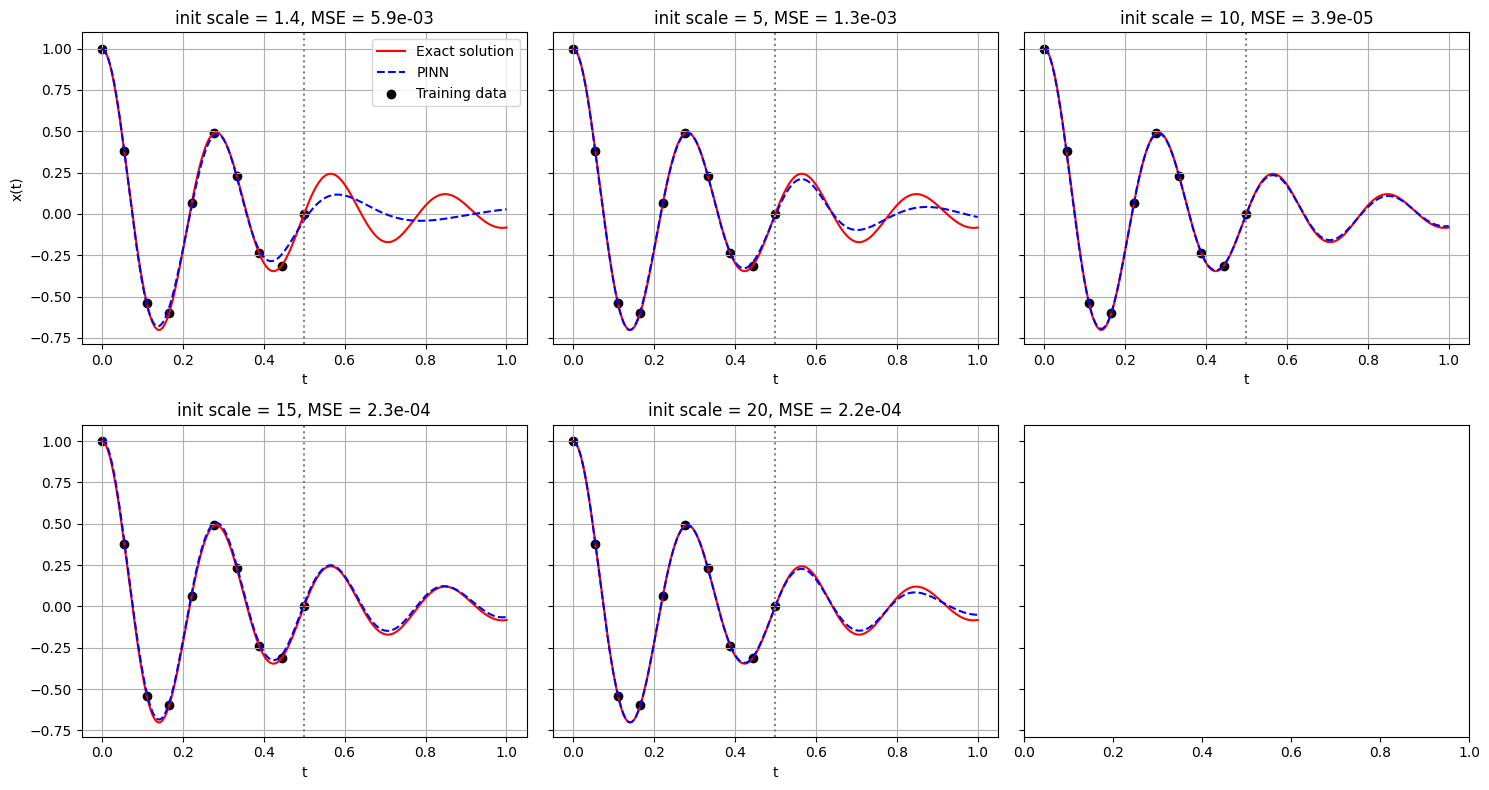

In [15]:
init_scales = [np.sqrt(2/1), 5, 10, 15, 20]
lam_phys = 1e-5  # best performer from above
lam_IC = 1

results_scale = {}
for init_scale in init_scales:
    params, losses = train_PINN(lam_phys, lam_IC, epochs, lr, M, init_scale, t_data, x_data, t_collocation)
    results_scale[init_scale] = (params, losses)
    
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, s in zip(axes.flatten(), init_scales):
    W1, b1, W2, b2 = results_scale[s][0]
    y_plot, _, _ = network_output_and_derivatives(t_plot, W1, b1, W2, b2)
    error = np.mean((y_plot - x_true)**2)
    ax.plot(t_plot, x_true, color="red", label="Exact solution")
    ax.plot(t_plot, y_plot, "--", color="blue", label="PINN")
    ax.scatter(t_data, x_data, color="black", label="Training data")
    ax.axvline(0.5, color="gray", linestyle=":")
    ax.set_title(f"init scale = {s:.2g}, MSE = {error:.1e}")
    ax.set_xlabel("t")
    ax.grid(True)
axes[0, 0].set_ylabel("x(t)")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

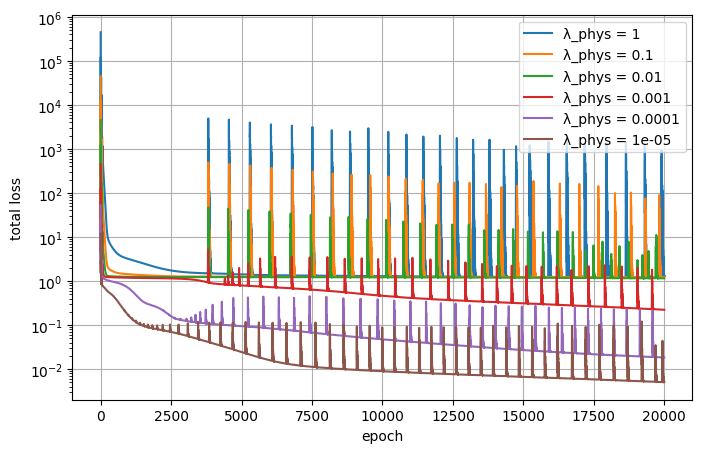

In [16]:
plt.figure(figsize=(8, 5))
for lam_phys in lam_phys_vals:
    plt.semilogy(results[lam_phys][1], label=f"λ_phys = {lam_phys:g}")
plt.xlabel("epoch")
plt.ylabel("total loss")
plt.legend()
plt.grid(True)
plt.show()

## Task 2.6

W1: max relative error = 3.01e-16
b1: max relative error = 1.13e-15
W2: max relative error = 6.51e-16
b2: max relative error = 0.00e+00


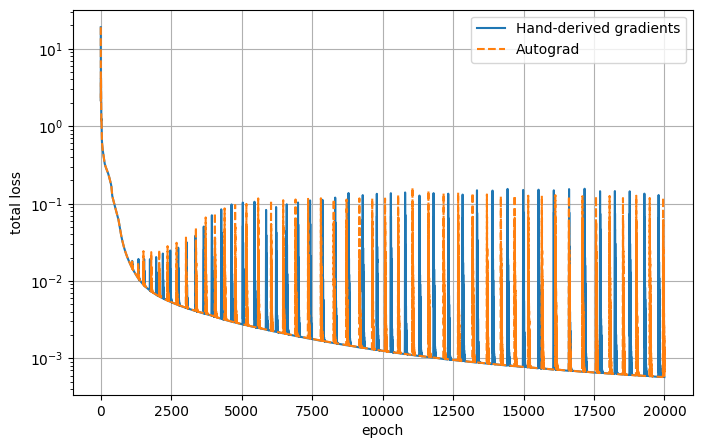

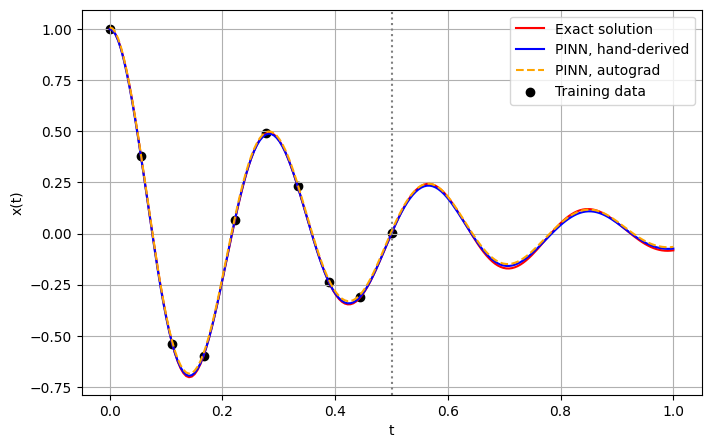

max difference between the two final predictions: 0.010947513115029117


In [19]:
import torch

def network_output_and_derivatives_torch(t, W1, b1, W2, b2):
    z = torch.outer(t, W1) + b1
    
    sigma = torch.tanh(z)
    sigma_1 = 1 - sigma**2
    sigma_2 = -2 * sigma * sigma_1
    
    y = torch.sum(W2 * sigma, dim=1) + b2
    y_1 = torch.sum(W2 * sigma_1 * W1, dim=1)
    y_2 = torch.sum(W2 * sigma_2 * W1**2, dim=1)
    
    return y, y_1, y_2

def total_loss_torch(W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data_t, x_data_t, t_collocation_t):
    y, _, _ = network_output_and_derivatives_torch(t_data_t, W1, b1, W2, b2)
    L_data = torch.mean((y - x_data_t)**2)
    
    y_c, y_1_c, y_2_c = network_output_and_derivatives_torch(t_collocation_t, W1, b1, W2, b2)
    r = y_2_c + mu * y_1_c + k * y_c
    L_phys = torch.mean(r**2)
    
    t_0 = torch.tensor([0.0], dtype=torch.float64)
    y_0, y_1_0, _ = network_output_and_derivatives_torch(t_0, W1, b1, W2, b2)
    L_IC = (y_0[0] - 1)**2 + (y_1_0[0])**2
    
    L = L_data + lam_phys * L_phys + lam_IC * L_IC
    return L

def train_PINN_autograd(lam_phys, lam_IC, epochs, lr, M, init_scale, t_data_t, x_data_t, t_collocation_t):
    rng = np.random.default_rng(1312)
    W1_t = torch.tensor(rng.normal(scale=init_scale, size=M), dtype=torch.float64, requires_grad=True)
    b1_t = torch.tensor(rng.normal(scale=init_scale, size=M), dtype=torch.float64, requires_grad=True)
    W2_t = torch.tensor(rng.normal(scale=(np.sqrt(2/M)), size=M), dtype=torch.float64, requires_grad=True)
    b2_t = torch.tensor([0.0], dtype=torch.float64, requires_grad=True)
    
    optimizer = torch.optim.Adam([W1_t, b1_t, W2_t, b2_t], lr)
    
    losses = []
    params = ()
    for epoch in range(epochs):
        L = total_loss_torch(W1_t, b1_t, W2_t, b2_t, mu, k, lam_phys, lam_IC, t_data_t, x_data_t, t_collocation_t)
        
        dW1, db1, dW2, db2 = torch.autograd.grad(L, [W1_t, b1_t, W2_t, b2_t])
        W1_t.grad = dW1
        b1_t.grad = db1
        W2_t.grad = dW2
        b2_t.grad = db2
        
        losses.append(L.item())
        optimizer.step()
    
    params = (W1_t.detach().numpy(), b1_t.detach().numpy(), W2_t.detach().numpy(), b2_t.item())
    return params, losses

t_data, x_data = data_points(10)
t_collocation = np.linspace(0, 1, 50)
t_data_t = torch.tensor(t_data, dtype=torch.float64)
x_data_t = torch.tensor(x_data, dtype=torch.float64)
t_collocation_t = torch.tensor(t_collocation, dtype=torch.float64)

mu = 5
k = 500
M = 64
lr = 0.01
epochs = 20_000
init_scale = 10
lam_phys = 1e-5
lam_IC = 1

rng = np.random.default_rng(1312)
W1 = rng.normal(scale=init_scale, size=M)
b1 = rng.normal(scale=init_scale, size=M)
W2 = rng.normal(scale=np.sqrt(2/M), size=M)
b2 = 0.0

args = (W1, b1, W2, b2, mu, k, lam_phys, lam_IC, t_data, x_data, t_collocation)
hand_grads = [grad_W1(*args), grad_b1(*args), grad_W2(*args), grad_b2(*args)]

W1_t = torch.tensor(W1, requires_grad=True)
b1_t = torch.tensor(b1, requires_grad=True)
W2_t = torch.tensor(W2, requires_grad=True)
b2_t = torch.tensor([b2], dtype=torch.float64, requires_grad=True)
L = total_loss_torch(W1_t, b1_t, W2_t, b2_t, mu, k, lam_phys, lam_IC, t_data_t, x_data_t, t_collocation_t)
auto_grads = torch.autograd.grad(L, [W1_t, b1_t, W2_t, b2_t])

for name, hand, auto in zip(["W1", "b1", "W2", "b2"], hand_grads, auto_grads):
    auto = auto.numpy()
    rel_error = np.max(np.abs(hand - auto) / np.max(np.abs(auto)))
    print(f"{name}: max relative error = {rel_error:.2e}")


params_hand, losses_hand = train_PINN(lam_phys, lam_IC, epochs, lr, M, init_scale, t_data, x_data, t_collocation)
params_auto, losses_auto = train_PINN_autograd(lam_phys, lam_IC, epochs, lr, M, init_scale,
                                               t_data_t, x_data_t, t_collocation_t)


plt.figure(figsize=(8, 5))
plt.semilogy(losses_hand, label="Hand-derived gradients")
plt.semilogy(losses_auto, "--", label="Autograd")
plt.xlabel("epoch")
plt.ylabel("total loss")
plt.legend()
plt.grid(True)
plt.show()


t_plot = np.linspace(0, 1, 200)
x_true = exact_solution(t_plot)
y_hand, _, _ = network_output_and_derivatives(t_plot, *params_hand)
y_auto, _, _ = network_output_and_derivatives(t_plot, *params_auto)

plt.figure(figsize=(8, 5))
plt.plot(t_plot, x_true, color="red", label="Exact solution")
plt.plot(t_plot, y_hand, color="blue", label="PINN, hand-derived")
plt.plot(t_plot, y_auto, "--", color="orange", label="PINN, autograd")
plt.scatter(t_data, x_data, color="black", label="Training data")
plt.axvline(0.5, color="gray", linestyle=":")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.grid(True)
plt.show()

print("max difference between the two final predictions:", np.max(np.abs(y_hand - y_auto)))


## Task 2.7

soft: x(0) - 1 = 8.72e-03,  x'(0) = 1.40e-02
hard: x(0) - 1 = 0.00e+00,  x'(0) = -0.00e+00


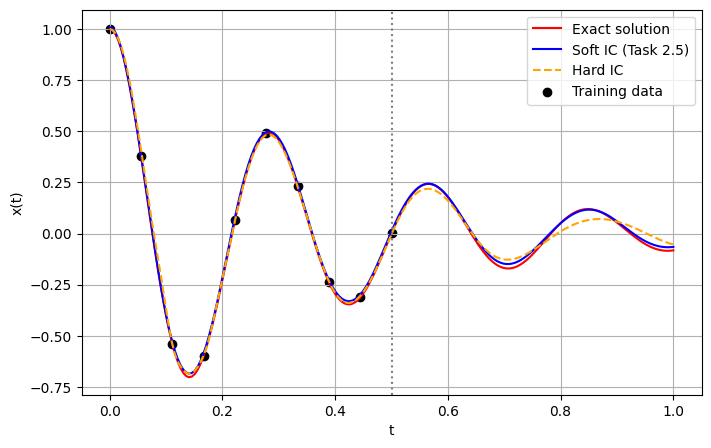

MSE on (0.5, 1), soft: 0.0001350646718034516
MSE on (0.5, 1), hard: 0.0011260388642448135


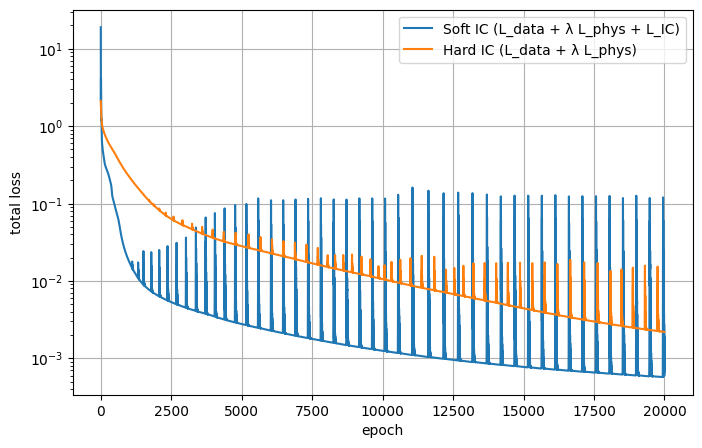

In [21]:
def network_output_and_derivatives_hard_torch(t, W1, b1, W2, b2):
    y, y_1, y_2 = network_output_and_derivatives_torch(t, W1, b1, W2, b2)
    
    x = 1 + t**2 * y
    x_1 = 2 * t * y + t**2 * y_1
    x_2 = 2 * y + 4 * t * y_1 + t**2 * y_2
    
    return x, x_1, x_2

def total_loss_hard_torch(W1, b1, W2, b2, mu, k, lam_phys, t_data_t, x_data_t, t_collocation_t):
    x, _, _ = network_output_and_derivatives_hard_torch(t_data_t, W1, b1, W2, b2)
    L_data = torch.mean((x - x_data_t)**2)
    
    x_c, x_1_c, x_2_c = network_output_and_derivatives_hard_torch(t_collocation_t, W1, b1, W2, b2)
    r = x_2_c + mu * x_1_c + k * x_c
    L_phys = torch.mean(r**2)
    
    L = L_data + lam_phys * L_phys
    return L

def train_PINN_hard(lam_phys, epochs, lr, M, init_scale, t_data_t, x_data_t, t_collocation_t):
    rng = np.random.default_rng(1312)
    W1_t = torch.tensor(rng.normal(scale=init_scale, size=M), dtype=torch.float64, requires_grad=True)
    b1_t = torch.tensor(rng.normal(scale=init_scale, size=M), dtype=torch.float64, requires_grad=True)
    W2_t = torch.tensor(rng.normal(scale=(np.sqrt(2/M)), size=M), dtype=torch.float64, requires_grad=True)
    b2_t = torch.tensor([0.0], dtype=torch.float64, requires_grad=True)
    
    optimizer = torch.optim.Adam([W1_t, b1_t, W2_t, b2_t], lr)
    
    losses = []
    for epoch in range(epochs):
        L = total_loss_hard_torch(W1_t, b1_t, W2_t, b2_t, mu, k, lam_phys, t_data_t, x_data_t, t_collocation_t)
        
        dW1, db1, dW2, db2 = torch.autograd.grad(L, [W1_t, b1_t, W2_t, b2_t])
        W1_t.grad = dW1
        b1_t.grad = db1
        W2_t.grad = dW2
        b2_t.grad = db2
        
        losses.append(L.item())
        optimizer.step()
    
    params = (W1_t.detach().numpy(), b1_t.detach().numpy(), W2_t.detach().numpy(), b2_t.item())
    return params, losses

def network_output_and_derivatives_hard(t, W1, b1, W2, b2):
    y, y_1, y_2 = network_output_and_derivatives(t, W1, b1, W2, b2)
        
    x = 1 + t**2 * y
    x_1 = 2 * t * y + t**2 * y_1
    x_2 = 2 * y + 4 * t * y_1 + t**2 * y_2
    
    return x, x_1, x_2

lam_phys = 1e-5
lam_IC = 1
params_hard, losses_hard = train_PINN_hard(lam_phys, epochs, lr, M, init_scale,
                                           t_data_t, x_data_t, t_collocation_t)
params_soft, losses_soft = train_PINN_autograd(lam_phys, lam_IC, epochs, lr, M, init_scale,
                                               t_data_t, x_data_t, t_collocation_t)

t0 = np.array([0.0])
x0_soft, v0_soft, _ = network_output_and_derivatives(t0, *params_soft)
x0_hard, v0_hard, _ = network_output_and_derivatives_hard(t0, *params_hard)
print(f"soft: x(0) - 1 = {x0_soft[0] - 1:.2e},  x'(0) = {v0_soft[0]:.2e}")
print(f"hard: x(0) - 1 = {x0_hard[0] - 1:.2e},  x'(0) = {v0_hard[0]:.2e}")

t_plot = np.linspace(0, 1, 200)
x_true = exact_solution(t_plot)
y_soft, _, _ = network_output_and_derivatives(t_plot, *params_soft)
y_hard, _, _ = network_output_and_derivatives_hard(t_plot, *params_hard)

plt.figure(figsize=(8, 5))
plt.plot(t_plot, x_true, color="red", label="Exact solution")
plt.plot(t_plot, y_soft, color="blue", label="Soft IC (Task 2.5)")
plt.plot(t_plot, y_hard, "--", color="orange", label="Hard IC")
plt.scatter(t_data, x_data, color="black", label="Training data")
plt.axvline(0.5, color="gray", linestyle=":")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.grid(True)
plt.show()

mask = t_plot > 0.5
print("MSE on (0.5, 1), soft:", np.mean((y_soft[mask] - x_true[mask])**2))
print("MSE on (0.5, 1), hard:", np.mean((y_hard[mask] - x_true[mask])**2))

plt.figure(figsize=(8, 5))
plt.semilogy(losses_soft, label="Soft IC (L_data + λ L_phys + L_IC)")
plt.semilogy(losses_hard, label="Hard IC (L_data + λ L_phys)")
plt.xlabel("epoch")
plt.ylabel("total loss")
plt.legend()
plt.grid(True)
plt.show()